# MNIST — tuned multilayer perceptron (MLP)

This notebook trains the assignment's fully connected neural network. It uses the **same stratified 50,000 training / 10,000 validation / 10,000 test split as CNN.ipynb and Random_forest_.ipynb**. The test set is reserved for evaluating the selected model after tuning.

**Run in order:** in Google Colab, choose *Runtime → Run all*. TensorFlow and scikit-learn must be installed in the environment. GPU is optional. For a local environment, install `tensorflow`, `scikit-learn`, `numpy`, `pandas`, and `matplotlib` first. Record the actual versions below rather than guessing version pins for deployment.

The notebook writes `models/mlp_final.keras`, tuning results, plots, and evaluation metadata. Training results are intentionally empty until you run it; the original 98.20% result does not describe this revised experiment.

**Team study notes — restored from the original notebook.**



#Imports


In [1]:
import json
import os
import platform
import shutil
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import mnist
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split

# Render saved figures inline when executed in a notebook kernel.
from IPython import get_ipython
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

# Allocate GPU memory as needed rather than reserving the entire device.
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

if os.environ.get('MNIST_REQUIRE_GPU') == '1' and not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Local GPU training requested, but TensorFlow cannot see a GPU.')

SEED = 42
keras.utils.set_random_seed(SEED)  # Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()

# Works when launched from the repository root or its notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
MODEL_DIR = PROJECT_ROOT / 'models'
CHECKPOINT_DIR = MODEL_DIR / 'mlp_checkpoints'
RESULT_DIR = PROJECT_ROOT / 'results' / 'mlp'
for folder in (MODEL_DIR, CHECKPOINT_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

environment = {
    'python': sys.version.split()[0],
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'scikit-learn': sklearn.__version__,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'matplotlib': plt.matplotlib.__version__,
    'platform': platform.platform(),
    'gpu_devices': [d.name for d in tf.config.list_physical_devices('GPU')],
    'gpu_details': [tf.config.experimental.get_device_details(d) for d in tf.config.list_physical_devices('GPU')],
    'logical_cpus': os.cpu_count(),
    'processor': platform.processor(),
}
print(json.dumps(environment, indent=2))
print('Project directory:', PROJECT_ROOT)


I0000 00:00:1791672231.750160    4582 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791672233.079340    4582 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


{
  "python": "3.12.3",
  "tensorflow": "2.21.0",
  "keras": "3.15.1",
  "scikit-learn": "1.9.1",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "matplotlib": "3.11.2",
  "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39",
  "gpu_devices": [
    "/physical_device:GPU:0"
  ],
  "gpu_details": [
    {
      "compute_capability": [
        8,
        9
      ],
      "device_name": "NVIDIA GeForce RTX 4060 Laptop GPU"
    }
  ],
  "logical_cpus": 20,
  "processor": "x86_64"
}
Project directory: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1


**Team study notes — restored from the original notebook.**



#Data


## 1. Shared data preparation

MNIST supplies 60,000 development images and a separate 10,000-image test set. We split the development set using `test_size=10000`, `random_state=42`, and `stratify=y_train_full`, exactly as the other two notebooks do.

Convert images to `float32`, divide by 255 to obtain values in [0, 1], and flatten each 28×28 image into 784 features. Keep labels as integers 0–9 and use `sparse_categorical_crossentropy`. **One-hot encoding is optional:** integer class labels with the sparse loss are valid classification targets; they do not turn the task into regression.

**Team study notes — restored from the original notebook.**



 one-hot encoding for the labels.

Instead of representing labels as a single number (which might cause the network to incorrectly interpret values as continuous, e.g., predicting 4.5 for an image between 4 and 5), the code converts them into a vector of length 10.

Structure: This vector contains all zeros, except for a "1" at the index corresponding to the actual digit.
Purpose: This transformation enables the neural network to output the probability of an image belonging to each specific class, which is standard practice for classification tasks.

**Correction:** integer digit labels work correctly with sparse categorical cross-entropy. One-hot encoding is an alternative label format; it does not prevent a classification network from becoming a regression model. The executed cells below use integer labels and the sparse loss.

**Team study notes — restored from the original notebook.**



one-hot encoding is like a multiple-choice answer key.

Instead of telling the computer that a picture is a "number 5" (which might confuse it into thinking it's something between 4 and 6), we give it 10 separate boxes (labeled 0 to 9).

When the computer looks at an image, it puts a 1 in the correct box and a 0 in all the others.
This makes it very clear to the computer exactly which digit it is looking at, which helps it learn to be accurate.

**Correction:** integer digit labels work correctly with sparse categorical cross-entropy. One-hot encoding is an alternative label format; it does not prevent a classification network from becoming a regression model. The executed cells below use integer labels and the sparse loss.

**Team study notes — restored from the original notebook.**



#Prepare data


In [2]:
(X_train_full, y_train_full), (X_test_raw, y_test) = mnist.load_data()
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=10000, random_state=SEED, stratify=y_train_full,
)

def prepare_mlp_images(images):
    """For raw MNIST arrays (N, 28, 28), return float32 features (N, 784)."""
    images = np.asarray(images)
    if images.ndim != 3 or images.shape[1:] != (28, 28):
        raise ValueError('Expected raw MNIST images with shape (N, 28, 28).')
    return (images.astype('float32') / 255.0).reshape(len(images), 784)

X_train = prepare_mlp_images(X_train_raw)
X_val = prepare_mlp_images(X_val_raw)
X_test = prepare_mlp_images(X_test_raw)

assert X_train.shape == (50000, 784)
assert X_val.shape == (10000, 784)
assert X_test.shape == (10000, 784)
assert X_train.dtype == np.float32
assert 0.0 <= X_train.min() <= X_train.max() <= 1.0
assert set(np.unique(y_train)) == set(range(10))
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Training label counts:', np.bincount(y_train))


Train: (50000, 784) Validation: (10000, 784) Test: (10000, 784)
Training label counts: [4936 5618 4965 5109 4868 4518 4932 5221 4876 4957]


## 2. Controlled hyperparameter experiments

Use a small planned search rather than changing settings based on test accuracy. Every trial starts with fresh weights and the same seed, data, maximum epoch budget, and stopping rule. Each alternative changes one setting from A, which makes its effect easier to explain. This is a controlled search, not an exhaustive grid; it does not explore interactions between settings.

| Trial | Hidden layers | Learning rate | Batch size | L2 penalty | Question |
|---|---|---|---|---|---|
| A | 128, 128 | 0.001 | 128 | 0 | Baseline |
| B | 256, 128 | 0.001 | 128 | 0 | Does a wider network help? |
| C | 128, 128 | 0.0003 | 128 | 0 | Does a smaller learning rate help? |
| D | 128, 128 | 0.001 | 512 | 0 | Does the original batch size help? |
| E | 128, 128 | 0.001 | 128 | 0.0001 | Does regularization improve generalization? |

All computational layers are Dense layers, with ReLU hidden activations and a 10-class softmax output. L2 penalizes weights without adding another layer. This keeps the architecture within the assignment's “fully connected layers only” wording.

For each trial, save the checkpoint with minimum validation loss. **Choose among those checkpoints by highest validation accuracy**, breaking ties with lower validation loss and then fewer parameters. This rule is set before training. Early stopping allows at most 20 epochs and stops after 3 epochs without validation-loss improvement. Epoch counts can differ; all trials follow the same stopping policy.

**Team study notes — restored from the original notebook.**



# The actual mlp

**Team study notes — restored from the original notebook.**



This code builds a neural network that takes **784 input values** and predicts **one of 10 classes**—for example, recognizing digits from 0 to 9.

```python
model = Sequential()
```

Creates an empty model where layers run **in order**. Each layer’s output becomes the next layer’s input.

### 1. First hidden layer

```python
model.add(Dense(128, input_shape=(784,), activation='relu'))
```

- Receives **784 values** per sample, such as a flattened 28 × 28 image.
- Contains **128 neurons**, each connected to all 784 inputs.
- Uses **ReLU**: negative values become zero; positive values stay unchanged.
- Produces **128 values** that represent patterns learned from the input.

### 2. Second hidden layer

```python
model.add(Dense(128, activation='relu'))
```

Adds another layer of **128 neurons**.

It receives the 128 outputs from the previous layer and learns further combinations of those patterns. You don’t need to specify `input_shape` again because Keras infers it.

### 3. Dropout

```python
model.add(Dropout(0.25))
```

During training, randomly sets **25% of the incoming values to zero** at each step.

This helps reduce **overfitting**, where the model memorizes training examples but performs poorly on new examples. Dropout is turned off when evaluating or making predictions.

### 4. Output layer

```python
model.add(Dense(10, activation='softmax'))
```

Creates **10 output neurons**, one for each class.

**Softmax** turns their results into probabilities that sum to 1. For example:

```text
Digit 0: 0.01
Digit 1: 0.02
Digit 2: 0.90
Other digits combined: 0.07
```

The model predicts **digit 2**, since it has the highest probability.

### 5. Configure training

```python
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)
```

`compile()` configures how the model will learn; **it does not train it yet**.

| Setting | Meaning |
|---|---|
| `loss='categorical_crossentropy'` | Measures how far the predicted probabilities are from the correct class. Lower is better. |
| `optimizer='adam'` | Adjusts the weights and biases during training to reduce the loss. |
| `metrics=['accuracy']` | Reports the proportion of predictions that are correct. |

**Label format matters:** `categorical_crossentropy` expects **one-hot labels**. For digit 2, that looks like:

```python
[0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
```

If your labels are integers such as `2`, use `sparse_categorical_crossentropy` instead.

### 6. Display the model

```python
model.summary()
```

Prints the layers, their output shapes, and their parameter counts:

| Layer | Output shape | Trainable parameters |
|---|---|---:|
| First Dense | `(None, 128)` | 100,480 |
| Second Dense | `(None, 128)` | 16,512 |
| Dropout | `(None, 128)` | 0 |
| Output Dense | `(None, 10)` | 1,290 |
| **Total** | | **118,282** |

**`None` represents the batch size**, which can vary. Dense parameters are calculated as:

\[
(\text{number of inputs}\times\text{number of neurons})+\text{number of biases}
\]

Dropout has zero parameters because it has no weights or biases to learn.

The complete flow is **784 inputs → 128 neurons → 128 neurons → dropout → 10 class probabilities**. Training starts when you call `model.fit(...)`.
# Parameters are the weights and biases learned during training.
# Dense parameters = (inputs * neurons) + neurons (one bias per neuron).
# First Dense: 784 * 128 + 128 = 100,480
# Second Dense: 128 * 128 + 128 = 16,512
# Output Dense: 128 * 10 + 10 = 1,290
# Total: 118,282; Dropout, ReLU, and softmax add no trainable parameters.
#
# Overfitting: the model performs well on training data but poorly on unseen data.
# Common sign: training loss decreases while validation loss increases.
# Reduce it using more varied data, dropout, early stopping, fewer neurons/layers,
# weight regularization, and suitable data augmentation.

**Historical example:** these notes describe the original 128/128 network with Dropout and one-hot labels. The corrected experiments below use Dense computational layers only and integer labels. The original architecture explanation is retained for study; the executable builder is the source of truth.

In [3]:
MAX_EPOCHS = 20
PATIENCE = 3
EXPERIMENTS = [
    {'name': 'A', 'hidden_units': [128, 128], 'learning_rate': 0.001, 'batch_size': 128, 'l2': 0.0},
    {'name': 'B', 'hidden_units': [256, 128], 'learning_rate': 0.001, 'batch_size': 128, 'l2': 0.0},
    {'name': 'C', 'hidden_units': [128, 128], 'learning_rate': 0.0003, 'batch_size': 128, 'l2': 0.0},
    {'name': 'D', 'hidden_units': [128, 128], 'learning_rate': 0.001, 'batch_size': 512, 'l2': 0.0},
    {'name': 'E', 'hidden_units': [128, 128], 'learning_rate': 0.001, 'batch_size': 128, 'l2': 0.0001},
]

def build_mlp(hidden_units, learning_rate, l2):
    model = keras.Sequential(name='mnist_mlp')
    model.add(keras.Input(shape=(784,)))
    penalty = regularizers.l2(l2) if l2 > 0 else None
    for units in hidden_units:
        model.add(layers.Dense(units, activation='relu', kernel_regularizer=penalty))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

preview = build_mlp([128, 128], learning_rate=0.001, l2=0.0)
preview.summary()
del preview


Model: "mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

**Team study notes — restored from the original notebook.**



#Train

In [4]:
trial_results = []
histories = {}

def run_mlp(config):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_mlp(config['hidden_units'], config['learning_rate'], config['l2'])
    checkpoint_path = CHECKPOINT_DIR / f"mlp_{config['name']}.keras"
    # Prevent a checkpoint from an earlier run being mistaken for this trial.
    if checkpoint_path.exists():
        checkpoint_path.unlink()
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(checkpoint_path), monitor='val_loss', mode='min', save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_loss', mode='min', patience=PATIENCE,
            restore_best_weights=True,
        ),
        keras.callbacks.TerminateOnNaN(),
    ]
    start = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=MAX_EPOCHS, batch_size=config['batch_size'],
        callbacks=callbacks, verbose=2, shuffle=True,
    )
    train_seconds = time.perf_counter() - start
    values = history.history
    if not all(np.isfinite(values[key]).all() for key in ('loss', 'val_loss', 'accuracy', 'val_accuracy')):
        raise RuntimeError(f"Trial {config['name']} produced non-finite metrics; investigate before selecting a model.")
    if not checkpoint_path.exists():
        raise RuntimeError(f"No checkpoint saved for trial {config['name']}.")
    best_index = int(np.argmin(values['val_loss']))
    # Verify the metrics of the actual file that will be considered for deployment.
    saved_model = keras.models.load_model(checkpoint_path)
    val_loss, val_accuracy = saved_model.evaluate(X_val, y_val, verbose=0)
    row = {
        **config,
        'best_epoch': best_index + 1,
        'epochs_run': len(values['loss']),
        'val_loss': float(val_loss),
        'val_accuracy': float(val_accuracy),
        'train_accuracy_at_best_epoch': float(values['accuracy'][best_index]),
        'train_seconds': float(train_seconds),
        'parameters': int(saved_model.count_params()),
        'checkpoint': str(checkpoint_path.relative_to(PROJECT_ROOT)),
    }
    pd.DataFrame(values).rename_axis('epoch_index').to_csv(RESULT_DIR / f"history_{config['name']}.csv")
    histories[config['name']] = values
    print(f"Trial {config['name']}: best epoch {row['best_epoch']}, validation accuracy {val_accuracy:.4%}, training {train_seconds:.1f}s")
    return row

for config in EXPERIMENTS:
    trial_results.append(run_mlp(config))
    pd.DataFrame(trial_results).to_csv(RESULT_DIR / 'tuning_results_partial.csv', index=False)

results = pd.DataFrame(trial_results)
results.to_csv(RESULT_DIR / 'tuning_results.csv', index=False)
print(results[['name', 'hidden_units', 'learning_rate', 'batch_size', 'l2',
               'best_epoch', 'epochs_run', 'val_accuracy', 'val_loss', 'train_seconds', 'parameters']].to_string(index=False))


Epoch 1/20


E0000 00:00:1791672235.992041    4582 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1791672242.487081    4582 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


391/391 - 7s - 18ms/step - accuracy: 0.9044 - loss: 0.3402 - val_accuracy: 0.9511 - val_loss: 0.1737


Epoch 2/20


...

391/391 - 5s - 13ms/step - accuracy: 0.9911 - loss: 0.0742 - val_accuracy: 0.9727 - val_loss: 0.1326


Epoch 9/20


391/391 - 5s - 12ms/step - accuracy: 0.9928 - loss: 0.0689 - val_accuracy: 0.9730 - val_loss: 0.1364


E0000 00:00:1791672500.440144    4582 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Trial E: best epoch 6, validation accuracy 97.4100%, training 47.6s
name hidden_units  learning_rate  batch_size     l2  best_epoch  epochs_run  val_accuracy  val_loss  train_seconds  parameters
   A   [128, 128]         0.0010         128 0.0000           7          10        0.9727  0.096733      49.889133      118282
   B   [256, 128]         0.0010         128 0.0000           5           8        0.9747  0.087385      39.742084      235146
   C   [128, 128]         0.0003         128 0.0000          17          20        0.9739  0.095748      95.957191      118282
   D   [128, 128]         0.0010         512 0.0000          12          15        0.9714  0.099770      20.787459      118282
   E   [128, 128]         0.0010         128 0.0001           6           9        0.9741  0.130026      47.552713      118282


## 3. Learning curves and model selection

Look for training loss decreasing while validation loss increases, or a persistent training/validation accuracy gap. Training accuracy includes any training-time behavior and is not a substitute for validation accuracy. One seeded run per setting is a starting point; repeated seeds would make small differences more convincing if time permits.

L2 adds a regularization term to reported loss, so cross-trial loss values with different penalties are not pure predictive cross-entropy. Validation accuracy is the primary selection criterion here; validation loss is only a tie-breaker.

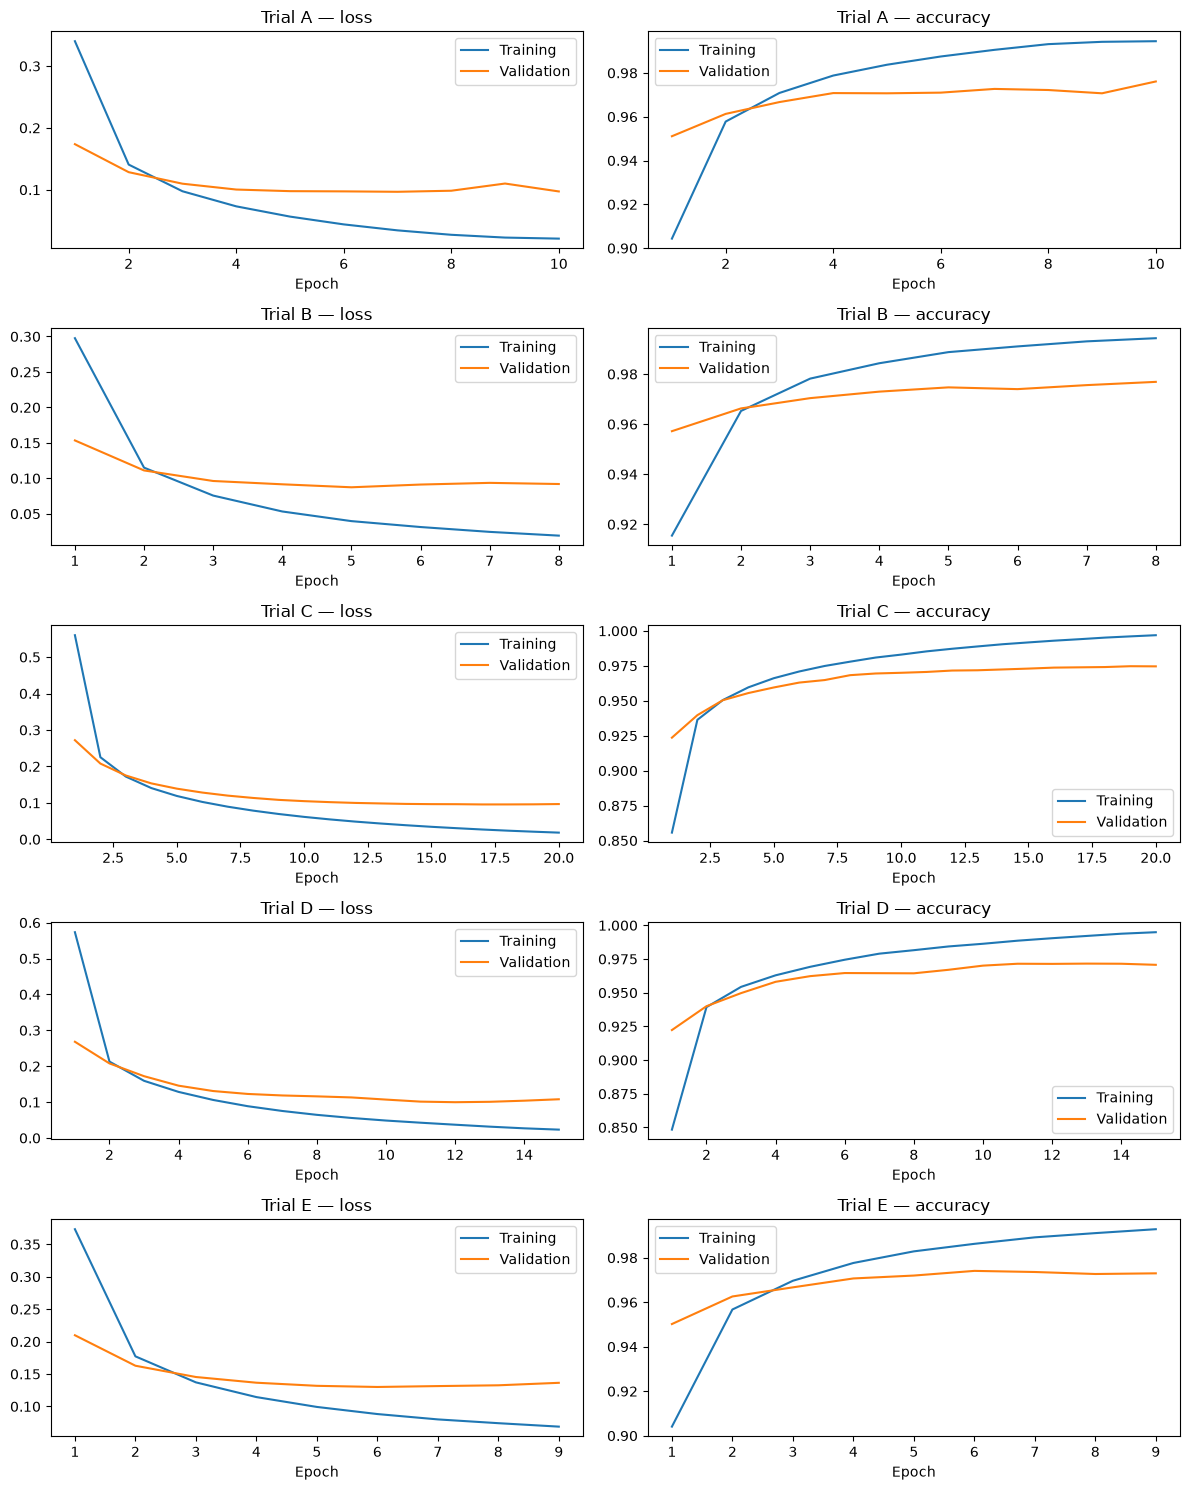

Chosen trial: B
Hidden units: [256, 128]
Learning rate: 0.001 Batch size: 128 L2: 0.0
Selected epoch: 5 Validation accuracy: 0.9746999740600586
Saved model: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1/models/mlp_final.keras


In [5]:
fig, axes = plt.subplots(len(EXPERIMENTS), 2, figsize=(12, 3 * len(EXPERIMENTS)))
for row, config in enumerate(EXPERIMENTS):
    h = histories[config['name']]
    epochs = np.arange(1, len(h['loss']) + 1)
    axes[row, 0].plot(epochs, h['loss'], label='Training')
    axes[row, 0].plot(epochs, h['val_loss'], label='Validation')
    axes[row, 0].set_title(f"Trial {config['name']} — loss")
    axes[row, 1].plot(epochs, h['accuracy'], label='Training')
    axes[row, 1].plot(epochs, h['val_accuracy'], label='Validation')
    axes[row, 1].set_title(f"Trial {config['name']} — accuracy")
    for ax in axes[row]:
        ax.set_xlabel('Epoch')
        ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / 'learning_curves.png', dpi=150)
plt.show()

ranked = results.sort_values(
    ['val_accuracy', 'val_loss', 'parameters', 'name'],
    ascending=[False, True, True, True],
)
winner = ranked.iloc[0].to_dict()
FINAL_PATH = MODEL_DIR / 'mlp_final.keras'
# Copy the exact selected checkpoint; do not retrain on the test set.
shutil.copy2(PROJECT_ROOT / winner['checkpoint'], FINAL_PATH)
print('Chosen trial:', winner['name'])
print('Hidden units:', winner['hidden_units'])
print('Learning rate:', winner['learning_rate'], 'Batch size:', winner['batch_size'], 'L2:', winner['l2'])
print('Selected epoch:', winner['best_epoch'], 'Validation accuracy:', winner['val_accuracy'])
print('Saved model:', FINAL_PATH)


## 4. Final evaluation from the saved model

Only now evaluate the selected checkpoint on the test set. Do not change hyperparameters in response to the test score. Accuracy plus per-digit precision, recall, F1, and a confusion matrix describe both overall performance and common confusions.

Inference timing measures a batch of 10,000 predictions after a warm-up. It excludes loading and includes Keras prediction overhead. Record the hardware; do not compare GPU and CPU training times as if they measure algorithm speed on identical hardware. A batch timing also does not establish one-drawing response time in Streamlit.

**Team study notes — restored from the original notebook.**



#Evaluate


In [6]:
keras.backend.clear_session()
load_start = time.perf_counter()
mlp_loaded = keras.models.load_model(FINAL_PATH)
load_seconds = time.perf_counter() - load_start

# Warm up using validation data, leaving test evaluation to the next prediction.
_ = mlp_loaded.predict(X_val[:128], batch_size=128, verbose=0)
start = time.perf_counter()
test_probs = mlp_loaded.predict(X_test, batch_size=128, verbose=0)
inference_seconds = time.perf_counter() - start
assert test_probs.shape == (10000, 10)
assert np.isfinite(test_probs).all()
assert np.allclose(test_probs.sum(axis=1), 1.0, atol=1e-5)
test_pred = np.argmax(test_probs, axis=1)
test_accuracy = float(accuracy_score(y_test, test_pred))
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, test_pred, average='macro', zero_division=0,
)
# Predictive cross-entropy excludes any L2 weight penalty.
true_class_probs = test_probs[np.arange(len(y_test)), y_test]
test_crossentropy = float(-np.log(np.clip(true_class_probs, 1e-7, 1.0)).mean())
report = classification_report(y_test, test_pred, labels=list(range(10)), output_dict=True, zero_division=0)
cm = confusion_matrix(y_test, test_pred, labels=list(range(10)))

print(f'Test accuracy: {test_accuracy:.4%}')
print(f'Macro F1: {macro_f1:.4f}')
print(f'Predictive cross-entropy: {test_crossentropy:.4f}')
print(f'Model size: {FINAL_PATH.stat().st_size / (1024 ** 2):.2f} MiB')
print(f'Loading: {load_seconds:.2f}s; 10,000 predictions after warm-up: {inference_seconds:.2f}s')
print(classification_report(y_test, test_pred, labels=list(range(10)), digits=4, zero_division=0))
pd.DataFrame(report).T.to_csv(RESULT_DIR / 'classification_report.csv')
pd.DataFrame(cm, index=range(10), columns=range(10)).to_csv(RESULT_DIR / 'confusion_matrix.csv')


Test accuracy: 97.6200%
Macro F1: 0.9761
Predictive cross-entropy: 0.0811
Model size: 2.72 MiB
Loading: 0.16s; 10,000 predictions after warm-up: 0.43s
              precision    recall  f1-score   support

           0     0.9828    0.9888    0.9858       980
           1     0.9894    0.9850    0.9872      1135
           2     0.9729    0.9748    0.9739      1032
           3     0.9620    0.9762    0.9690      1010
           4     0.9865    0.9684    0.9774       982
           5     0.9840    0.9664    0.9751       892
           6     0.9822    0.9802    0.9812       958
           7     0.9852    0.9689    0.9769      1028
           8     0.9643    0.9702    0.9672       974
           9     0.9538    0.9812    0.9673      1009

    accuracy                         0.9762     10000
   macro avg     0.9763    0.9760    0.9761     10000
weighted avg     0.9763    0.9762    0.9762     10000



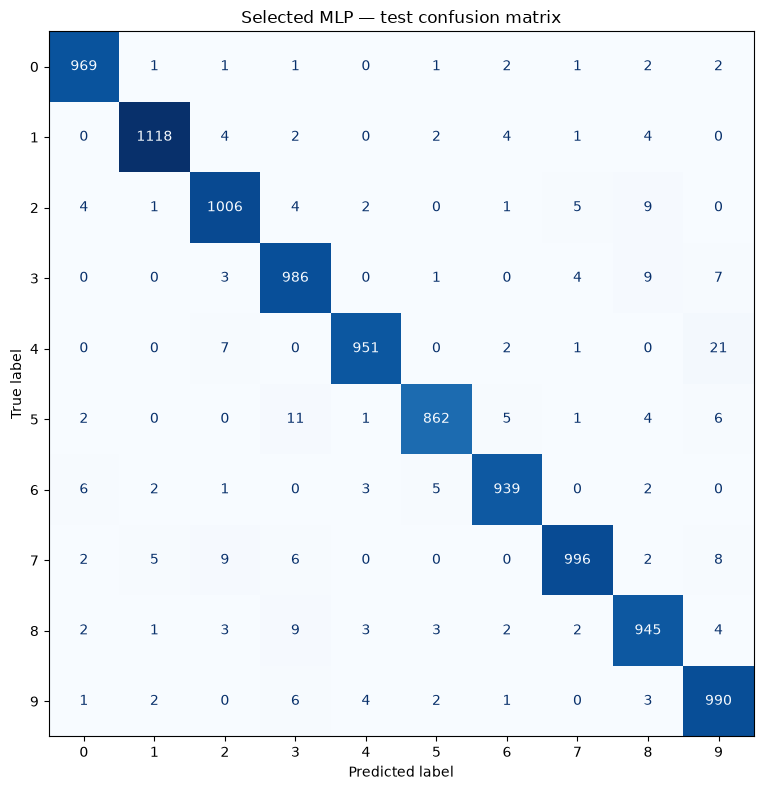

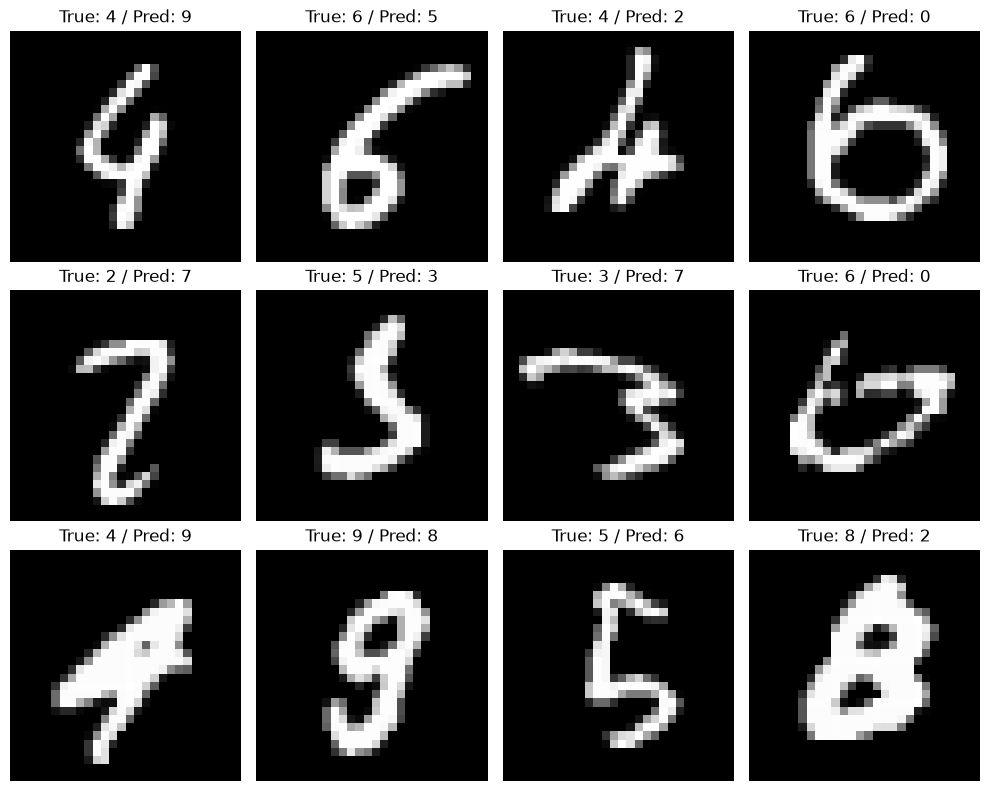

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Selected MLP — test confusion matrix')
fig.tight_layout()
fig.savefig(RESULT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

wrong = np.flatnonzero(test_pred != y_test)[:12]
if len(wrong):
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, wrong):
        ax.imshow(X_test_raw[index], cmap='gray')
        ax.set_title(f'True: {y_test[index]} / Pred: {test_pred[index]}')
    fig.tight_layout()
    fig.savefig(RESULT_DIR / 'misclassified_examples.png', dpi=150)
    plt.show()
else:
    print('No test errors in this run.')


## 5. Check saving/reloading and export the experiment record

Compare predictions from two independent loads on validation samples. The full test predictions above already came from the saved final model. Save preprocessing and environment details beside the model so the app can reproduce its expected inputs.

In [8]:
second_load = keras.models.load_model(FINAL_PATH, compile=False)
validation_probs_1 = mlp_loaded.predict(X_val[:32], verbose=0)
validation_probs_2 = second_load.predict(X_val[:32], verbose=0)
np.testing.assert_allclose(validation_probs_1, validation_probs_2, rtol=1e-5, atol=1e-6)
assert second_load.input_shape == (None, 784)
assert second_load.output_shape == (None, 10)
del second_load
print('Reload check passed; input (N, 784), output (N, 10).')

metrics = {
    'model': 'MLP',
    'selected_trial': str(winner['name']),
    'best_epoch': int(winner['best_epoch']),
    'validation_accuracy': float(winner['val_accuracy']),
    'test_accuracy': test_accuracy,
    'test_predictive_crossentropy': test_crossentropy,
    'macro_precision': float(macro_precision),
    'macro_recall': float(macro_recall),
    'macro_f1': float(macro_f1),
    'parameters': int(mlp_loaded.count_params()),
    'selected_trial_train_seconds': float(winner['train_seconds']),
    'total_search_train_seconds': float(results['train_seconds'].sum()),
    'load_seconds': float(load_seconds),
    'test_inference_seconds_10000_after_warmup': float(inference_seconds),
    'file_size_mib': FINAL_PATH.stat().st_size / (1024 ** 2),
}
metadata = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': 'MNIST',
    'split': {'train': 50000, 'validation': 10000, 'test': 10000,
              'random_state': SEED, 'stratify': True},
    'preprocessing': {'input_shape': [784], 'dtype': 'float32',
                      'normalization': 'raw pixel / 255.0',
                      'polarity': 'bright digit on dark background',
                      'labels': 'integer digits 0-9'},
    'selection': 'Highest validation accuracy at each trial minimum-val-loss checkpoint; tie: lower val_loss, fewer parameters, trial name',
    'hyperparameters': next(c for c in EXPERIMENTS if c['name'] == winner['name']),
    'training': {'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'seed': SEED},
    'environment': environment,
    'metrics': metrics,
}
(MODEL_DIR / 'mlp_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
(RESULT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
pd.DataFrame([metrics]).to_csv(RESULT_DIR / 'comparison_row.csv', index=False)
(RESULT_DIR / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print(json.dumps(metrics, indent=2))


Reload check passed; input (N, 784), output (N, 10).
{
  "model": "MLP",
  "selected_trial": "B",
  "best_epoch": 5,
  "validation_accuracy": 0.9746999740600586,
  "test_accuracy": 0.9762,
  "test_predictive_crossentropy": 0.08108966797590256,
  "macro_precision": 0.9762967572850784,
  "macro_recall": 0.9760074804209051,
  "macro_f1": 0.9761017851997325,
  "parameters": 235146,
  "selected_trial_train_seconds": 39.74208363099933,
  "total_search_train_seconds": 253.92858036599955,
  "load_seconds": 0.16246714099997916,
  "test_inference_seconds_10000_after_warmup": 0.42617298499953904,
  "file_size_mib": 2.7155160903930664
}


## 6. Conclusions for the team report

Fill these in from the outputs after running:

1. Which trial won, and how much did validation accuracy improve over A? If A won, explain why the alternatives did not improve the result.
2. What do the learning curves show about generalization? Name the chosen epoch and stopping behavior.
3. Which digits are most often confused? Include the confusion matrix and a few errors.
4. Compare the final MLP with Random Forest and CNN on the **same split**: test accuracy, macro F1, training time with hardware, parameter count/complexity, model size, and measured app latency.
5. Explain why the final project recommendation balances performance and deployment cost. The original CNN result of 99.01% and Random Forest result of 96.95% are recorded notebook outputs, not rerun measurements from this notebook.

Do not write a conclusion claiming this revised MLP achieved 98.20% without running it. CPU/GPU differences and stopping behavior also need to be stated when comparing timings.

### Streamlit input contract

Load `models/mlp_final.keras` with `keras.models.load_model(path, compile=False)`. Feed an array with shape **(1, 784)**, dtype `float32`, values in [0, 1], and a **bright digit on a dark background**. Take `argmax` of the ten output scores.

A drawing must first be converted to grayscale, cropped to its content, resized with aspect ratio preserved, placed and centered in a 28×28 dark image, then normalized and flattened. Reject blank drawings. Inspect a 28×28 preview in the app. This notebook's `prepare_mlp_images` expects raw 0–255 MNIST images; do not call it on already-normalized data and divide by 255 again.

The required drawing canvas, clear button, model selector, and Predict button remain separate app work. Add picture upload only after the core app and documentation are complete, as planned.


## 7. Optional Colab download

The next cell creates a ZIP containing the final model, metadata, and this run's result files (excluding experiment checkpoints). In Colab it downloads the ZIP. Outside Colab it prints its location. Keep only the three final models in the eventual deployment repository; intermediate tuning checkpoints are not required app assets.

In [9]:
import zipfile

archive_path = PROJECT_ROOT / 'mlp_deliverables.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in [FINAL_PATH, MODEL_DIR / 'mlp_metadata.json', *sorted(RESULT_DIR.glob('*'))]:
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(PROJECT_ROOT)))
print('Deliverables ZIP:', archive_path)
try:
    from google.colab import files
except ImportError:
    print('Local environment: retrieve the ZIP from the path above.')
else:
    files.download(str(archive_path))


Deliverables ZIP: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1/mlp_deliverables.zip
Local environment: retrieve the ZIP from the path above.


## Original code comments retained for study

These verbatim excerpts preserve comments attached to code that changed during correction. They are historical study material; run the corrected executable cells above. NumPy-only seeding does not seed all TensorFlow randomness, and MNIST may download on first use.

Original code cell 2:

```python
#is to display plots directly below the code cell that generates them within the notebook interface. Without this line, you would typically need to manually type plt.show()
#y setting the seed to a specific number (like 0), you ensure that every time you run your code, the "random" calculations—such as initializing your model's weights—produce the exact same result.
```

Original code cell 4:

```python
#
```

Original code cell 11:

```python
#normalize data
```

Original code cell 12:

```python
#Reshaping the data into 1D vector to pass it (flattening)
```

Original code cell 15:

```python
# Sequential() is the way of adding multiple layers in keras
```
